# 17 — Birləşdirilmiş böyük dataset (v3)

**Məqsəd:** dörd açıq mənbəni bir datasetdə birləşdirmək, mənbələr arası təmizləmək və bütün modelləri (baza və normallaşdırma ilə)
birləşdirilmiş testdə, hər mənbənin öz testində, leave-one-dataset-out (LODO) rejimində və əl ilə yazılmış payload-larda yoxlamaq.

**Tərkib** (hər sətir: `query`, `label`, `source`):

| Mənbə | Nə götürülür |
|---|---|
| Kaggle `Modified_SQL_Dataset` | `clean_v2` — hamısı |
| HttpParamsDataset | `sqli` + `norm` — hamısı |
| WAF-A-MoLE | dublikatlar və iki sinifdə olanlar çıxarıldıqdan sonra hər sinifdən 40 000 təsadüfi sorğu (seed 42) |
| open-appsec legitimate | 15-dəki kimi çıxarılmış parametr dəyərlərindən 40 000 təsadüfi unikal, boş olmayan dəyər (label 0, seed 42) |

Əl ilə yazılmış payload siyahıları (14) **yalnız test üçündür**: normallaşdırılmış forması payload-la üst-üstə düşən hər sətir datasetdən çıxarılır.

**Təmizləmə** (ardıcıllıqla, `src/v3.py::clean`): boş sətirlər → mənbə daxilində tam dublikatlar → normallaşdırılmış forması iki sinifdə olan
sorğular (bütün nüsxələri) → payload siyahıları ilə üst-üstə düşənlər → mənbələr arası tam dublikatlar → mənbələr arası normallaşdırılmış
dublikatlar. Mənbələr arası dublikatda prioritet: Kaggle → HttpParams → WAF-A-MoLE → open-appsec (ilk mənbədəki nüsxə qalır).

**Bölgü:** hər mənbə ayrıca qrup əsaslı 70/15/15 (qrup = normallaşdırılmış forma, `GroupShuffleSplit`), sonra hissələr birləşdirilir; seed 42–46.

**Modellər** (hər biri *baza* və *normallaşdırma* ilə): TF-IDF (char 1–5) + LR / Linear SVM / RF / NB, char-CNN (13-cü notebook-un arxitekturası).
Hiperparametrlər validation F1-ə görə: LR C ∈ {1, 10, 100}, SVM C ∈ {0.1, 1, 10}, RF 200 ağac, NB α ∈ {0.001, 0.01, 0.1}
(12/14-ün müdafiə gridləri; böyük dataset üçün baza gridi də bununla eynidir). CNN-in epoxa sayı aşağıdakı `CNN_EPOCHS`-dadır.

**Testlər:** (A) birləşdirilmiş test və hər mənbənin öz test hissəsi; (B) LODO — bir mənbə train/val-dan tam çıxarılır, yalnız onda (bütün sətirləri) test olunur;
(C) payload siyahıları üzrə recall, FPR — open-appsec test hissəsində. Hamısı **alternativ whitespace** ilə də: obfuskasiya yalnız zərərli sətirlərə,
birbaşa model girişinə tətbiq olunur (14-dəki kimi); boşluğu olmayan sətirlər dəyişmir.

In [1]:
import sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import v3
import handwritten as hw

for d in (v3.DATA, v3.RES, v3.FIG, v3.MODELS):
    d.mkdir(parents=True, exist_ok=True)
RES, FIG = v3.RES, v3.FIG

SEEDS = [42, 43, 44, 45, 46]
LODO_SEEDS = [42, 43, 44, 45, 46]      # TF-IDF modelləri
CNN_LODO_SEEDS = [42]                  # CNN LODO-da yalnız seed 42 (müddət səbəbindən, aşağıda qeyd olunur)
CNN_EPOCHS = 5

# Qrafik üslubu: sakit fon, nazik xətlər, yalnız dəyər oxunda zəif grid
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#2b2b2a", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titleweight": "bold", "axes.titlesize": 10, "legend.frameon": False,
    "grid.color": "#e4e3df", "grid.linewidth": 0.6,
})
CLS_COLOR = {"zərərli": "#eb6834", "təmiz": "#2a78d6"}
CFG_COLOR = {"baza": "#a3a29c", "norm.": "#2a78d6"}
SRC = [v3.SOURCE_LABEL[s] for s in v3.SOURCES]

## 1. Datasetin qurulması və təmizlənməsi

In [2]:
raw = v3.raw_sources()
df, report = v3.clean(raw)
report.to_csv(RES / "17_cleaning_report.csv")
out = df.rename(columns={"Query": "query", "Label": "label"})[["query", "label", "source"]]
out.to_csv(v3.DATA / "v3_combined.csv", index=False)
print(len(raw), "ilkin sətir ->", len(df), "yekun sətir")
report.rename(index=v3.SOURCE_LABEL)

180411 ilkin sətir -> 164380 yekun sətir


,ilkin,boş,mənbə daxilində tam dublikat,iki sinifdə (normallaşdırılmış forma),"payload siyahıları ilə üst-üstə (14, yalnız test)",mənbələr arası tam dublikat,mənbələr arası normallaşdırılmış dublikat,yekun,zərərli,təmiz
Kaggle,30255,0,0,5,163,0,0,30087,11203,18884
HttpParams,30156,0,0,1,5,7592,8189,14369,2271,12098
WAF-A-MoLE,80000,0,0,0,0,0,0,80000,40000,40000
open-appsec,40000,0,0,4,0,66,6,39924,0,39924
cəmi,180411,0,0,10,168,7658,8195,164380,53474,110906


## 2. EDA
### (a) Mənbə × sinif sayları

sinif,zərərli,təmiz,cəmi,zərərli %
source,,,,
Kaggle,11203,18884,30087,37.2
HttpParams,2271,12098,14369,15.8
WAF-A-MoLE,40000,40000,80000,50.0
open-appsec,0,39924,39924,0.0
cəmi,53474,110906,164380,32.5


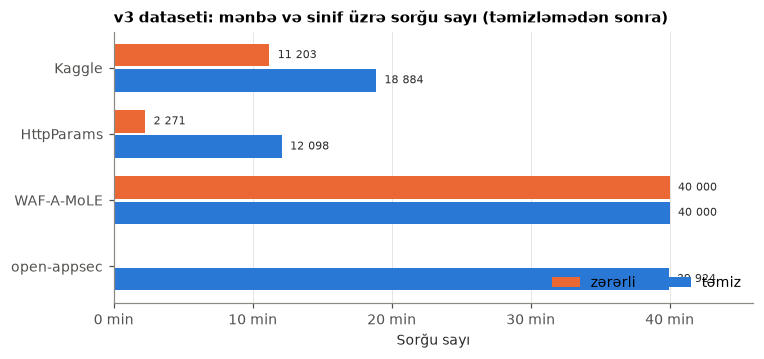

In [3]:
counts = (df.assign(sinif=df.Label.map({1: "zərərli", 0: "təmiz"}))
            .groupby(["source", "sinif"]).size().unstack(fill_value=0)
            .reindex(v3.SOURCES)[["zərərli", "təmiz"]])
counts["cəmi"] = counts.sum(axis=1)
counts["zərərli %"] = (100 * counts["zərərli"] / counts["cəmi"]).round(1)
counts.loc["cəmi"] = [counts["zərərli"].sum(), counts["təmiz"].sum(), counts["cəmi"].sum(),
                      round(100 * counts["zərərli"].sum() / counts["cəmi"].sum(), 1)]
counts.rename(index=v3.SOURCE_LABEL).to_csv(RES / "17_eda_counts.csv")
display(counts.rename(index=v3.SOURCE_LABEL))

fig, ax = plt.subplots(figsize=(7.5, 3.2))
y = np.arange(len(v3.SOURCES))
h = 0.38
for i, cls in enumerate(["zərərli", "təmiz"]):
    vals = counts.loc[v3.SOURCES, cls].to_numpy()
    bars = ax.barh(y + (i - 0.5) * h, vals, h - 0.04, color=CLS_COLOR[cls], label=cls)
    for b, v in zip(bars, vals):
        if v:
            ax.text(b.get_width() + 600, b.get_y() + b.get_height() / 2, f"{v:,}".replace(",", " "),
                    va="center", fontsize=7.5, color="#2b2b2a")
ax.set_yticks(y, SRC)
ax.invert_yaxis()
ax.xaxis.grid(True); ax.set_axisbelow(True)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v/1000:.0f} min"))
ax.set_xlabel("Sorğu sayı")
ax.set_xlim(0, counts.loc[v3.SOURCES, ["zərərli", "təmiz"]].to_numpy().max() * 1.15)
ax.set_title("v3 dataseti: mənbə və sinif üzrə sorğu sayı (təmizləmədən sonra)", loc="left")
ax.legend(loc="lower right", ncol=2)
fig.savefig(FIG / "17a_source_class_counts.png")
plt.show()

### (b) Sorğu uzunluğu (simvol), mənbə və sinif üzrə

C:\Users\Mehman\AppData\Local\Temp\ipykernel_21556\4000972947.py:10: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(groups, vert=False, widths=0.6, patch_artist=True, showfliers=True,


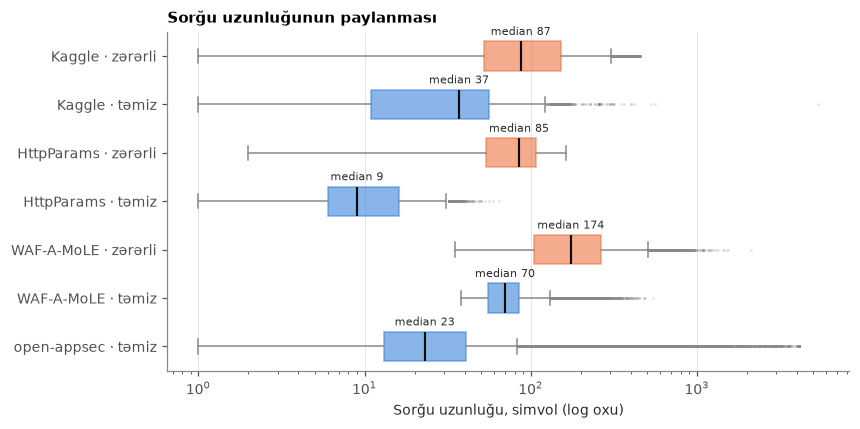

In [4]:
df["len"] = df.Query.str.len()
groups, labels, colors, meds = [], [], [], []
for s in v3.SOURCES:
    for lab, cls in ((1, "zərərli"), (0, "təmiz")):
        v = df.loc[(df.source == s) & (df.Label == lab), "len"]
        if len(v):
            groups.append(v.clip(lower=1).to_numpy()); labels.append(f"{v3.SOURCE_LABEL[s]} · {cls}")
            colors.append(CLS_COLOR[cls]); meds.append(v.median())
fig, ax = plt.subplots(figsize=(8, 4))
bp = ax.boxplot(groups, vert=False, widths=0.6, patch_artist=True, showfliers=True,
                flierprops=dict(marker=".", markersize=1.5, alpha=0.25, markeredgecolor="#8a8984"),
                medianprops=dict(color="#0b0b0b", linewidth=1.4), whiskerprops=dict(color="#8a8984"),
                capprops=dict(color="#8a8984"))
for patch, c in zip(bp["boxes"], colors):
    patch.set_facecolor(c); patch.set_alpha(0.55); patch.set_edgecolor(c)
ax.set_xscale("log")
ax.set_yticks(range(1, len(labels) + 1), labels)
ax.invert_yaxis()
for i, m in enumerate(meds, start=1):
    ax.text(m, i - 0.38, f"median {m:.0f}", ha="center", va="bottom", fontsize=7, color="#2b2b2a")
ax.xaxis.grid(True, which="major"); ax.set_axisbelow(True)
ax.set_xlabel("Sorğu uzunluğu, simvol (log oxu)")
ax.set_title("Sorğu uzunluğunun paylanması", loc="left")
fig.savefig(FIG / "17b_query_length_boxplot.png")
plt.show()
df.groupby(["source", "Label"]).len.describe()[["count", "25%", "50%", "75%", "max"]].to_csv(RES / "17_eda_length.csv")

### (c) Format artefaktları: mənbə × sinif üzrə faiz

,mənbə,sinif,n,double_space,newline,comment
0,Kaggle,zərərli,11203,95.22,0.00,52.21
1,Kaggle,təmiz,18884,29.80,0.00,0.04
2,HttpParams,zərərli,2271,0.00,0.00,66.36
3,HttpParams,təmiz,12098,0.00,0.00,0.00
4,WAF-A-MoLE,zərərli,40000,3.34,28.46,59.08
5,WAF-A-MoLE,təmiz,40000,0.00,0.00,0.00
6,open-appsec,təmiz,39924,0.44,0.35,1.12


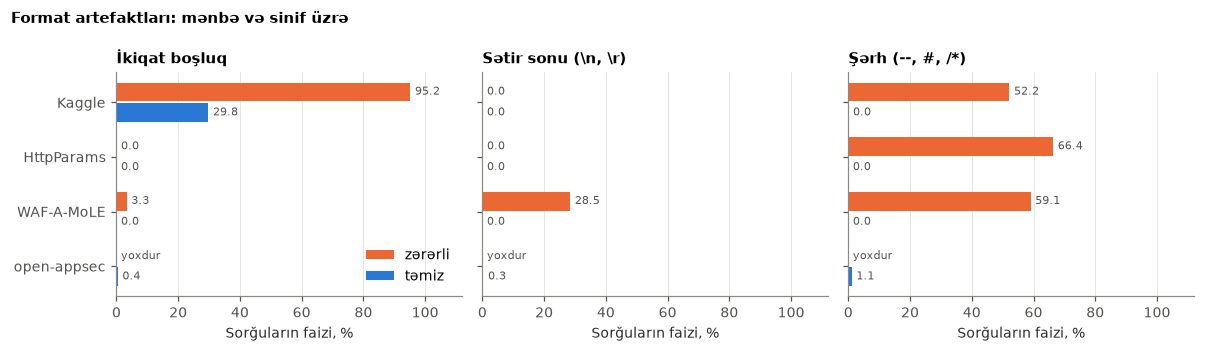

In [5]:
rows = []
for s in v3.SOURCES:
    for lab, cls in ((1, "zərərli"), (0, "təmiz")):
        q = df.loc[(df.source == s) & (df.Label == lab), "Query"]
        if len(q):
            rows.append({"mənbə": v3.SOURCE_LABEL[s], "sinif": cls, "n": len(q),
                         **{k: round(100 * f(q).mean(), 2) for k, f in v3.ART.items()}})
art = pd.DataFrame(rows)
art.to_csv(RES / "17_eda_format_artifacts.csv", index=False)
display(art)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
y = np.arange(len(SRC)); h = 0.38
for ax, (k, title) in zip(axes, v3.ART_LABEL.items()):
    for i, cls in enumerate(["zərərli", "təmiz"]):
        d = art[art.sinif == cls].set_index("mənbə").reindex(SRC)[k]
        bars = ax.barh(y + (i - 0.5) * h, d.fillna(0), h - 0.04, color=CLS_COLOR[cls], label=cls)
        for b, v in zip(bars, d):
            ax.text((0 if np.isnan(v) else v) + 1.5, b.get_y() + b.get_height() / 2,
                    "yoxdur" if np.isnan(v) else f"{v:.1f}", va="center", fontsize=7, color="#52514e")
    ax.set_title(title, loc="left"); ax.set_xlim(0, 112)
    ax.xaxis.grid(True); ax.set_axisbelow(True); ax.set_xlabel("Sorğuların faizi, %")
axes[0].set_yticks(y, SRC); axes[0].invert_yaxis()
axes[0].legend(loc="lower right")
fig.suptitle("Format artefaktları: mənbə və sinif üzrə", x=0.01, ha="left", fontweight="bold", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "17c_format_artifacts.png")
plt.show()

### (d) Mənbələr arası üst-üstə düşmə
Mənbələr arası təmizləmədən **əvvəl** (boşlar və mənbə daxilində dublikatlar çıxarıldıqdan sonra), normallaşdırılmış formada:
xana = sətirdəki mənbənin unikal normallaşdırılmış sorğularından neçə faizi sütundakı mənbədə də var.

,Kaggle,HttpParams,WAF-A-MoLE,open-appsec
Kaggle,NaN,52.336,0.0,0.143
HttpParams,52.344,NaN,0.0,0.212
WAF-A-MoLE,0.000,0.000,NaN,0.000
open-appsec,0.108,0.160,0.0,NaN


,Kaggle,HttpParams,WAF-A-MoLE,open-appsec
Kaggle,30161,15785,0,43
HttpParams,15785,30156,0,64
WAF-A-MoLE,0,0,80000,0
open-appsec,43,64,0,39982


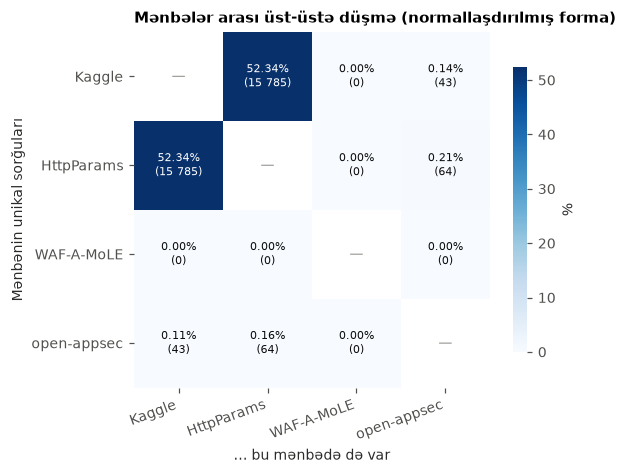

In [6]:
r0 = raw[raw.Query.str.strip() != ""].drop_duplicates(["source", "Query"]).copy()
r0["nk"] = r0.Query.map(v3.normalize)
keys = {s: set(r0.loc[r0.source == s, "nk"]) for s in v3.SOURCES}
ov = pd.DataFrame([[np.nan if a == b else 100 * len(keys[a] & keys[b]) / len(keys[a]) for b in v3.SOURCES]
                   for a in v3.SOURCES], index=SRC, columns=SRC)
ovn = pd.DataFrame([[len(keys[a] & keys[b]) for b in v3.SOURCES] for a in v3.SOURCES], index=SRC, columns=SRC)
ov.round(3).to_csv(RES / "17_eda_overlap_pct.csv"); ovn.to_csv(RES / "17_eda_overlap_counts.csv")
display(ov.round(3)); display(ovn)

fig, ax = plt.subplots(figsize=(5.4, 4.2))
im = ax.imshow(ov.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=max(1, np.nanmax(ov.to_numpy())))
for i in range(len(SRC)):
    for j in range(len(SRC)):
        if i == j:
            ax.text(j, i, "—", ha="center", va="center", color="#8a8984")
        else:
            v = ov.iat[i, j]
            ax.text(j, i, f"{v:.2f}%\n({ovn.iat[i, j]:,})".replace(",", " "), ha="center", va="center", fontsize=7.5,
                    color="white" if v > 0.6 * np.nanmax(ov.to_numpy()) else "#0b0b0b")
ax.set_xticks(range(len(SRC)), SRC, rotation=20, ha="right"); ax.set_yticks(range(len(SRC)), SRC)
ax.set_xlabel("… bu mənbədə də var"); ax.set_ylabel("Mənbənin unikal sorğuları")
for sp in ax.spines.values(): sp.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.set_label("%"); cb.outline.set_visible(False)
ax.set_title("Mənbələr arası üst-üstə düşmə (normallaşdırılmış forma)", loc="left")
fig.savefig(FIG / "17d_source_overlap_heatmap.png")
plt.show()

## 3. Bölgü (hər mənbə ayrıca 70/15/15, sonra birləşdirilir)

In [7]:
rows = []
for s in SEEDS:
    tr, va, te = v3.split(df, s)
    for part, d in (("train", tr), ("val", va), ("test", te)):
        for src, g in d.groupby("source"):
            rows.append({"seed": s, "hissə": part, "mənbə": v3.SOURCE_LABEL[src], "n": len(g), "zərərli": int(g.Label.sum())})
    if s == 42:
        for part, d in (("train", tr), ("val", va), ("test", te)):
            d.rename(columns={"Query": "query", "Label": "label"})[["query", "label", "source"]].to_csv(
                v3.DATA / f"v3_seed42_{part}.csv", index=False)
split_rep = pd.DataFrame(rows)
split_rep.to_csv(RES / "17_split_report.csv", index=False)
split_rep[split_rep.seed == 42].pivot_table(index="mənbə", columns="hissə", values="n", aggfunc="sum")[["train", "val", "test"]]

hissə,train,val,test
mənbə,,,
HttpParams,10058,2155,2156
Kaggle,21059,4510,4518
WAF-A-MoLE,56000,12000,12000
open-appsec,27945,5989,5990


## 4. Əsas təlim (5 seed) — test A və C
Modellər `models/v3/`-də keşlənir. Hər seed üçün: birləşdirilmiş test + hər mənbənin test hissəsi (A), payload siyahıları (C), normal və alternativ whitespace.

In [8]:
payloads = hw.load()[["Query", "Label"]]
raw_rows, model_info = [], []
for s in SEEDS:
    t0 = time.perf_counter()
    tr, va, te = v3.split(df, s)
    models, info = v3.train_models(s, tr, va, "main", cnn=True, cnn_epochs=CNN_EPOCHS)
    model_info += [{"seed": s, "model": k, **v} for k, v in info.items()]
    slices = {"Birləşdirilmiş test": np.ones(len(te), bool)}
    slices.update({f"Test: {v3.SOURCE_LABEL[src]}": (te.source == src).to_numpy() for src in v3.SOURCES})
    raw_rows += v3.cached_rows(f"main_{s}", lambda: v3.evaluate_sliced(models, te, slices, s, "main")
                               + v3.evaluate(models, {"Payload siyahıları (14)": payloads}, s, "main"))
    pd.DataFrame(raw_rows).to_csv(RES / "17_raw_main.csv", index=False)
    print(f"seed {s}: {time.perf_counter() - t0:.0f} s", flush=True)
main = pd.DataFrame(raw_rows)
pd.DataFrame(model_info).to_csv(RES / "17_model_selection.csv", index=False)
pd.DataFrame(model_info).pivot_table(index="model", columns="seed", values="param", aggfunc="first").loc[v3.MODEL_ORDER]

    main baza LR p=1 valF1=0.9952 (6 s)


    main baza LR p=10 valF1=0.9940 (4 s)


    main baza LR p=100 valF1=0.9947 (5 s)


    main baza SVM p=0.1 valF1=0.9964 (2 s)


    main baza SVM p=1 valF1=0.9975 (2 s)


    main baza SVM p=10 valF1=0.9974 (7 s)


... (106 outputs left out)

    main CNN baza seed 46: epochs=5 valF1=0.9985 (1274 s)


    main CNN norm. seed 46: epochs=5 valF1=0.9987 (1275 s)


seed 46: 3290 s


seed,42,43,44,45,46
model,,,,,
LR baza,1,10,100,10,10
LR norm.,100,10,100,10,10
SVM baza,1,1,10,1,1
SVM norm.,1,1,1,1,1
RF baza,200,200,200,200,200
RF norm.,200,200,200,200,200
NB baza,0.001,0.001,0.001,0.01,0.001
NB norm.,0.001,0.01,0.001,0.001,0.001
CNN baza,epochs=5,epochs=5,epochs=5,epochs=5,epochs=5


In [9]:
METRICS = ["accuracy", "precision", "recall", "f1", "roc_auc", "fpr"]
def agg(d, keys, metrics=METRICS):
    a = d.groupby(keys)[metrics].agg(["mean", "std"])
    return a

def fmt(a, metrics=METRICS):
    out = pd.DataFrame(index=a.index)
    for m in metrics:
        mu, sd = a[(m, "mean")], a[(m, "std")]
        if m == "roc_auc":
            out[m] = mu.map(lambda v: "—" if pd.isna(v) else f"{v:.4f}") + sd.map(lambda v: "" if pd.isna(v) else f" ± {v:.4f}")
        else:
            out[m] = (100 * mu).map(lambda v: "—" if pd.isna(v) else f"{v:.2f}") + (100 * sd).map(lambda v: "" if pd.isna(v) else f" ± {v:.2f}")
    return out

comb = main[main.test == "Birləşdirilmiş test"]
a_comb = agg(comb, ["input", "model"])
a_comb.to_csv(RES / "17_A_combined_mean_std.csv")
tA = {inp: fmt(a_comb.xs(inp, level="input")).loc[v3.MODEL_ORDER] for inp in ("normal", "alt_whitespace")}
tA["normal"].to_csv(RES / "17_A_combined_table.csv"); tA["alt_whitespace"].to_csv(RES / "17_A_combined_alt_ws_table.csv")
print("Birləşdirilmiş test — normal giriş (%, ROC-AUC 0–1; orta ± std, 5 seed)")
display(tA["normal"])
print("Birləşdirilmiş test — alternativ whitespace")
display(tA["alt_whitespace"])

Birləşdirilmiş test — normal giriş (%, ROC-AUC 0–1; orta ± std, 5 seed)


,accuracy,precision,recall,f1,roc_auc,fpr
model,,,,,,
LR baza,99.76 ± 0.04,99.70 ± 0.07,99.56 ± 0.13,99.63 ± 0.06,0.9996 ± 0.0002,0.14 ± 0.04
LR norm.,99.81 ± 0.02,99.71 ± 0.04,99.70 ± 0.07,99.71 ± 0.03,0.9997 ± 0.0002,0.14 ± 0.02
SVM baza,99.86 ± 0.02,99.73 ± 0.04,99.85 ± 0.03,99.79 ± 0.03,0.9998 ± 0.0001,0.13 ± 0.02
SVM norm.,99.86 ± 0.01,99.73 ± 0.04,99.84 ± 0.02,99.79 ± 0.02,0.9998 ± 0.0001,0.13 ± 0.02
RF baza,99.74 ± 0.02,99.58 ± 0.08,99.63 ± 0.03,99.60 ± 0.04,0.9998 ± 0.0001,0.21 ± 0.04
RF norm.,99.74 ± 0.03,99.57 ± 0.07,99.64 ± 0.09,99.60 ± 0.05,0.9998 ± 0.0001,0.21 ± 0.03
NB baza,99.80 ± 0.02,99.55 ± 0.07,99.84 ± 0.04,99.70 ± 0.04,0.9999 ± 0.0001,0.22 ± 0.03
NB norm.,99.82 ± 0.01,99.63 ± 0.03,99.83 ± 0.03,99.73 ± 0.01,0.9999 ± 0.0001,0.18 ± 0.02
CNN baza,99.87 ± 0.02,99.75 ± 0.02,99.86 ± 0.04,99.80 ± 0.03,0.9999 ± 0.0001,0.12 ± 0.01


Birləşdirilmiş test — alternativ whitespace


,accuracy,precision,recall,f1,roc_auc,fpr
model,,,,,,
LR baza,96.23 ± 1.39,99.67 ± 0.07,88.77 ± 4.25,93.86 ± 2.41,0.9985 ± 0.0007,0.14 ± 0.04
LR norm.,99.81 ± 0.02,99.71 ± 0.04,99.70 ± 0.07,99.71 ± 0.03,0.9997 ± 0.0002,0.14 ± 0.02
SVM baza,97.55 ± 0.30,99.71 ± 0.05,92.75 ± 0.87,96.10 ± 0.47,0.9994 ± 0.0001,0.13 ± 0.02
SVM norm.,99.86 ± 0.01,99.73 ± 0.04,99.84 ± 0.02,99.79 ± 0.02,0.9998 ± 0.0001,0.13 ± 0.02
RF baza,91.91 ± 0.55,99.44 ± 0.10,75.60 ± 1.85,85.89 ± 1.20,0.9983 ± 0.0003,0.21 ± 0.04
RF norm.,99.74 ± 0.03,99.57 ± 0.07,99.64 ± 0.09,99.60 ± 0.05,0.9998 ± 0.0001,0.21 ± 0.03
NB baza,98.25 ± 0.09,99.53 ± 0.08,95.08 ± 0.26,97.25 ± 0.14,0.9991 ± 0.0001,0.22 ± 0.03
NB norm.,99.82 ± 0.01,99.63 ± 0.03,99.83 ± 0.03,99.73 ± 0.01,0.9999 ± 0.0001,0.18 ± 0.02
CNN baza,98.80 ± 0.44,99.74 ± 0.02,96.56 ± 1.36,98.12 ± 0.70,0.9996 ± 0.0001,0.12 ± 0.01


In [10]:
# Hər mənbənin öz test hissəsi: F1, recall, FPR (normal) və recall (alt. whitespace)
per = main[main.test.str.startswith("Test: ")]
a_per = agg(per, ["test", "input", "model"])
a_per.to_csv(RES / "17_A_per_source_mean_std.csv")
def pm(m, inp, src):
    a = a_per.loc[(f"Test: {src}", inp)]
    mu, sd = 100 * a[(m, "mean")], 100 * a[(m, "std")]
    return [("—" if pd.isna(x) else f"{x:.2f} ± {y:.2f}") for x, y in zip(mu.loc[v3.MODEL_ORDER], sd.loc[v3.MODEL_ORDER])]
cols = {}
for src in SRC:
    if src == "open-appsec":
        cols[(src, "FPR")] = pm("fpr", "normal", src)
    else:
        cols[(src, "F1")] = pm("f1", "normal", src)
        cols[(src, "Recall")] = pm("recall", "normal", src)
        cols[(src, "FPR")] = pm("fpr", "normal", src)
        cols[(src, "Recall, alt. ws.")] = pm("recall", "alt_whitespace", src)
tA_src = pd.DataFrame(cols, index=v3.MODEL_ORDER)
tA_src.to_csv(RES / "17_A_per_source_table.csv")
tA_src

Kaggle                                              \
                     F1        Recall          FPR Recall, alt. ws.   
LR baza    99.44 ± 0.18  98.94 ± 0.35  0.04 ± 0.03    71.84 ± 10.46   
LR norm.   99.45 ± 0.10  99.00 ± 0.20  0.06 ± 0.05     99.00 ± 0.20   
SVM baza   99.66 ± 0.11  99.35 ± 0.18  0.01 ± 0.03     70.70 ± 2.50   
SVM norm.  99.62 ± 0.06  99.29 ± 0.09  0.02 ± 0.03     99.29 ± 0.09   
RF baza    99.44 ± 0.12  98.89 ± 0.23  0.00 ± 0.00     23.30 ± 2.81   
RF norm.   99.47 ± 0.18  98.94 ± 0.35  0.00 ± 0.00     98.94 ± 0.35   
NB baza    99.39 ± 0.16  99.31 ± 0.15  0.32 ± 0.18     78.82 ± 1.00   
NB norm.   99.46 ± 0.06  99.23 ± 0.14  0.18 ± 0.02     99.23 ± 0.14   
CNN baza   99.66 ± 0.13  99.36 ± 0.23  0.02 ± 0.03     91.94 ± 3.27   
CNN norm.  99.62 ± 0.11  99.25 ± 0.23  0.00 ± 0.00     99.25 ± 0.23   

              HttpParams                                               \
                      F1         Recall          FPR Recall, alt. ws.   
LR baza    100.00 ± 0.00  100.00 ± 0.00  0.00 ± 0.00     98.80 ± 0.91   
LR norm.    99.97 ± 0.07  100.00 ± 0.00  0.01 ± 0.02    100.00 ± 0.00   
SVM baza   100.00 ± 0.00  100.00 ± 0.00  0.00 ± 0.00     99.70 ± 0.30   
SVM norm.  100.00 ± 0.00  100.00 ± 0.00  0.00 ± 0.00    100.00 ± 0.00   
RF baza    100.00 ± 0.00  100.00 ± 0.00  0.00 ± 0.00     96.21 ± 1.25   
RF norm.   100.00 ± 0.00  100.00 ± 0.00  0.00 ± 0.00    100.00 ± 0.00   
NB baza     99.81 ± 0.26  100.00 ± 0.00  0.07 ± 0.09    100.00 ± 0.00   
NB norm.    99.88 ± 0.13  100.00 ± 0.00  0.04 ± 0.05    100.00 ± 0.00   
CNN baza   100.00 ± 0.00  100.00 ± 0.00  0.00 ± 0.00     99.70 ± 0.52   
CNN norm.  100.00 ± 0.00  100.00 ± 0.00  0.00 ± 0.00    100.00 ± 0.00   

             WAF-A-MoLE                                              \
                     F1        Recall          FPR Recall, alt. ws.   
LR baza    99.67 ± 0.07  99.71 ± 0.13  0.37 ± 0.09     92.95 ± 2.72   
LR norm.   99.77 ± 0.03  99.88 ± 0.09  0.34 ± 0.07     99.88 ± 0.09   
SVM baza   99.82 ± 0.03  99.98 ± 0.01  0.34 ± 0.05     98.52 ± 0.70   
SVM norm.  99.83 ± 0.03  99.99 ± 0.01  0.34 ± 0.05     99.99 ± 0.01   
RF baza    99.63 ± 0.04  99.82 ± 0.04  0.57 ± 0.11     89.06 ± 2.12   
RF norm.   99.63 ± 0.05  99.82 ± 0.03  0.57 ± 0.10     99.82 ± 0.03   
NB baza    99.84 ± 0.02  99.98 ± 0.01  0.30 ± 0.04     99.34 ± 0.27   
NB norm.   99.84 ± 0.03  99.99 ± 0.01  0.31 ± 0.05     99.99 ± 0.01   
CNN baza   99.86 ± 0.01  99.99 ± 0.01  0.28 ± 0.01     97.68 ± 0.99   
CNN norm.  99.85 ± 0.02  99.99 ± 0.01  0.29 ± 0.03     99.99 ± 0.01   

           open-appsec  
                   FPR  
LR baza    0.02 ± 0.02  
LR norm.   0.02 ± 0.02  
SVM baza   0.01 ± 0.01  
SVM norm.  0.01 ± 0.01  
RF baza    0.01 ± 0.01  
RF norm.   0.01 ± 0.01  
NB baza    0.13 ± 0.04  
NB norm.   0.10 ± 0.04  
CNN baza   0.04 ± 0.03  
CNN norm.  0.04 ± 0.02

In [11]:
# C: payload siyahıları — recall (normal, alt. whitespace); FPR open-appsec test hissəsində
pl = main[main.test == "Payload siyahıları (14)"]
oa_fpr = main[(main.test == "Test: open-appsec") & (main.input == "normal")]
tC = pd.DataFrame({
    "Recall": fmt(agg(pl[pl.input == "normal"], ["model"], ["recall"]), ["recall"]).recall,
    "Recall, alt. whitespace": fmt(agg(pl[pl.input == "alt_whitespace"], ["model"], ["recall"]), ["recall"]).recall,
    "FPR (open-appsec test)": fmt(agg(oa_fpr, ["model"], ["fpr"]), ["fpr"]).fpr,
}).loc[v3.MODEL_ORDER]
tC.to_csv(RES / "17_C_payload_table.csv")
print("n payload:", int(pl.n.iloc[0]))
tC

n payload: 1427


,Recall,"Recall, alt. whitespace",FPR (open-appsec test)
model,,,
LR baza,86.63 ± 1.71,77.62 ± 5.20,0.02 ± 0.02
LR norm.,91.17 ± 1.08,91.17 ± 1.08,0.02 ± 0.02
SVM baza,89.39 ± 0.61,72.71 ± 1.75,0.01 ± 0.01
SVM norm.,91.17 ± 0.61,91.17 ± 0.61,0.01 ± 0.01
RF baza,88.35 ± 3.35,38.32 ± 4.64,0.01 ± 0.01
RF norm.,91.49 ± 0.15,91.49 ± 0.15,0.01 ± 0.01
NB baza,90.95 ± 2.03,84.88 ± 2.12,0.13 ± 0.04
NB norm.,87.90 ± 2.12,87.90 ± 2.12,0.10 ± 0.04
CNN baza,90.74 ± 0.63,76.12 ± 2.45,0.04 ± 0.03


Ən yaxşı model (orta F1): CNN baza 99.80


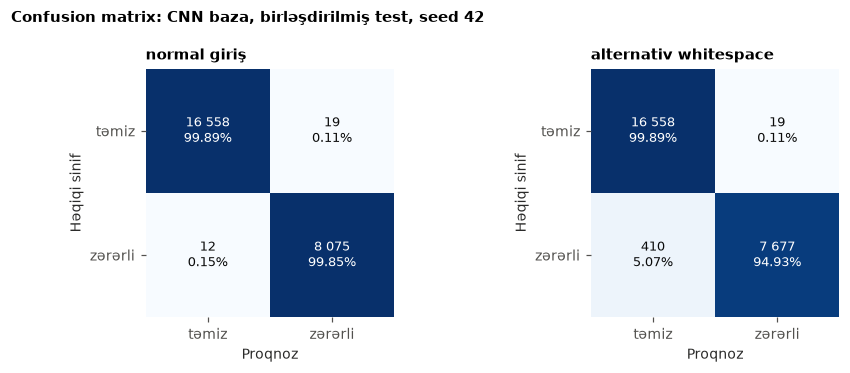

In [12]:
# Ən yaxşı model (birləşdirilmiş test, orta F1) — seed 42 confusion matrix
f1m = a_comb.xs("normal", level="input")[("f1", "mean")]
best = f1m.idxmax()
print("Ən yaxşı model (orta F1):", best, f"{100 * f1m.max():.2f}")
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.4))
cms = {}
for ax, inp, ttl in zip(axes, ("normal", "alt_whitespace"), ("normal giriş", "alternativ whitespace")):
    r = comb[(comb.model == best) & (comb.seed == 42) & (comb.input == inp)].iloc[0]
    cm = np.array([[r.tn, r.fp], [r.fn, r.tp]])
    cms[inp] = cm
    ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            frac = cm[i, j] / cm[i].sum()
            ax.text(j, i, f"{cm[i, j]:,}\n{100 * frac:.2f}%".replace(",", " "), ha="center", va="center",
                    color="white" if frac > 0.6 else "#0b0b0b", fontsize=8.5)
    ax.set_xticks([0, 1], ["təmiz", "zərərli"]); ax.set_yticks([0, 1], ["təmiz", "zərərli"])
    ax.set_xlabel("Proqnoz"); ax.set_ylabel("Həqiqi sinif"); ax.set_title(ttl, loc="left")
    for sp in ax.spines.values(): sp.set_visible(False)
fig.suptitle(f"Confusion matrix: {best}, birləşdirilmiş test, seed 42", x=0.01, ha="left", fontweight="bold", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "17_confusion_matrix_best.png")
plt.show()
pd.DataFrame({inp: v.ravel() for inp, v in cms.items()},
             index=["tn", "fp", "fn", "tp"]).to_csv(RES / "17_confusion_matrix_best_seed42.csv")

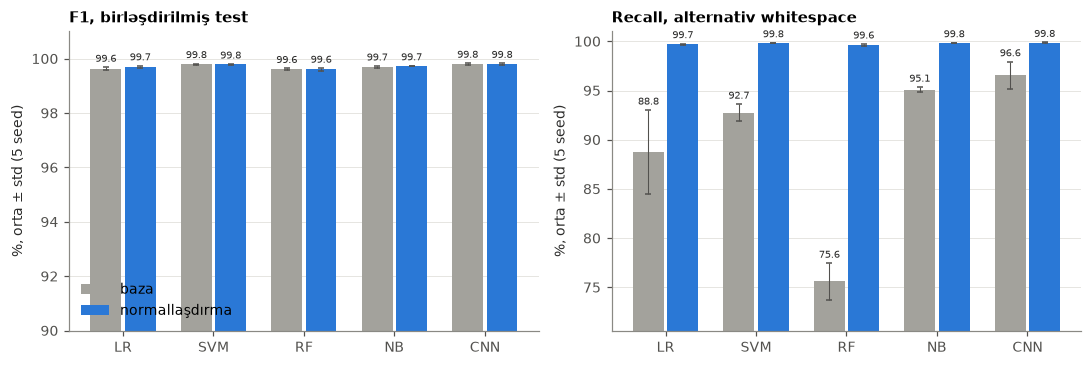

In [13]:
# Qrafik: birləşdirilmiş testdə F1 və alt. whitespace recall-u, baza vs normallaşdırma
fam = ["LR", "SVM", "RF", "NB", "CNN"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=False)
for ax, (inp, m, ttl) in zip(axes, [("normal", "f1", "F1, birləşdirilmiş test"),
                                     ("alt_whitespace", "recall", "Recall, alternativ whitespace")]):
    a = a_comb.xs(inp, level="input")
    x = np.arange(len(fam)); w = 0.38
    for i, cfg in enumerate(v3.CONFIGS):
        mu = np.array([100 * a.loc[f"{f} {cfg}", (m, "mean")] for f in fam])
        sd = np.array([100 * a.loc[f"{f} {cfg}", (m, "std")] for f in fam])
        b = ax.bar(x + (i - 0.5) * w, mu, w - 0.04, yerr=sd, capsize=2, color=CFG_COLOR[cfg],
                   error_kw=dict(elinewidth=0.7, ecolor="#52514e"), label="normallaşdırma" if cfg == "norm." else "baza")
        ax.bar_label(b, fmt="%.1f", fontsize=6.5, padding=2, color="#2b2b2a")
    ax.set_xticks(x, fam); ax.set_title(ttl, loc="left")
    ax.yaxis.grid(True); ax.set_axisbelow(True); ax.set_ylabel("%, orta ± std (5 seed)")
    lo = min(100 * a[(m, "mean")].min() - 5, 90)
    ax.set_ylim(max(0, lo), 101)
axes[0].legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIG / "17_models_combined_test.png")
plt.show()

## 5. Test B — leave-one-dataset-out (LODO)
Hər dəfə bir mənbə train və val-dan tam çıxarılır; model qalan mənbələrin train hissəsində öyrədilir və çıxarılan mənbənin **bütün** sətirlərində test olunur.
open-appsec-də yalnız təmiz sinif var — orada yalnız FPR mənalıdır. TF-IDF modelləri `LODO_SEEDS`, CNN `CNN_LODO_SEEDS` ilə.

In [14]:
lodo_rows = []
for held in v3.SOURCES:
    full = df[df.source == held].reset_index(drop=True)
    for s in LODO_SEEDS:
        t0 = time.perf_counter()
        tr, va, _ = v3.split(df, s)
        tr, va = tr[tr.source != held].reset_index(drop=True), va[va.source != held].reset_index(drop=True)
        models, _ = v3.train_models(s, tr, va, f"lodo-{held}", cnn=s in CNN_LODO_SEEDS, cnn_epochs=CNN_EPOCHS)
        lodo_rows += v3.cached_rows(f"lodo_{held}_{s}",
                                    lambda: v3.evaluate(models, {f"LODO: {v3.SOURCE_LABEL[held]}": full}, s, "lodo"))
        pd.DataFrame(lodo_rows).to_csv(RES / "17_raw_lodo.csv", index=False)
        print(f"LODO {held} seed {s}: {time.perf_counter() - t0:.0f} s", flush=True)
lodo = pd.DataFrame(lodo_rows)

    lodo-kaggle baza LR p=1 valF1=0.9953 (4 s)


    lodo-kaggle baza LR p=10 valF1=0.9967 (6 s)


    lodo-kaggle baza LR p=100 valF1=0.9965 (4 s)


    lodo-kaggle baza SVM p=0.1 valF1=0.9963 (2 s)


    lodo-kaggle baza SVM p=1 valF1=0.9973 (2 s)


    lodo-kaggle baza SVM p=10 valF1=0.9971 (5 s)


... (418 outputs left out)

    lodo-openappsec norm. NB p=0.001 valF1=0.9864 (0 s)


    lodo-openappsec norm. NB p=0.01 valF1=0.9862 (0 s)


    lodo-openappsec norm. NB p=0.1 valF1=0.9857 (0 s)


LODO openappsec seed 46: 478 s


In [15]:
a_lodo = agg(lodo, ["test", "input", "model"])
a_lodo.to_csv(RES / "17_B_lodo_mean_std.csv")
nseed = lodo.groupby(["test", "model"]).seed.nunique().unstack(0)
cols = {}
for src in SRC:
    t = f"LODO: {src}"
    def g(m, inp):
        a = a_lodo.loc[(t, inp)]
        return [("—" if pd.isna(a.loc[k, (m, "mean")]) else f"{100 * a.loc[k, (m, 'mean')]:.2f}"
                 + ("" if pd.isna(a.loc[k, (m, "std")]) else f" ± {100 * a.loc[k, (m, 'std')]:.2f}")) for k in v3.MODEL_ORDER]
    if src == "open-appsec":
        cols[(src, "FPR")] = g("fpr", "normal")
    else:
        cols[(src, "Recall")] = g("recall", "normal"); cols[(src, "FPR")] = g("fpr", "normal")
        cols[(src, "F1")] = g("f1", "normal"); cols[(src, "Recall, alt. ws.")] = g("recall", "alt_whitespace")
tB = pd.DataFrame(cols, index=v3.MODEL_ORDER)
tB.to_csv(RES / "17_B_lodo_table.csv")
print("Seed sayı:"); display(nseed.loc[v3.MODEL_ORDER])
tB

Seed sayı:


test,LODO: HttpParams,LODO: Kaggle,LODO: WAF-A-MoLE,LODO: open-appsec
model,,,,
LR baza,5,5,5,5
LR norm.,5,5,5,5
SVM baza,5,5,5,5
SVM norm.,5,5,5,5
RF baza,5,5,5,5
RF norm.,5,5,5,5
NB baza,5,5,5,5
NB norm.,5,5,5,5
CNN baza,1,1,1,1


Kaggle                                                \
                 Recall            FPR            F1 Recall, alt. ws.   
LR baza    80.68 ± 1.81  18.16 ± 12.50  76.89 ± 6.13     59.37 ± 6.67   
LR norm.   86.47 ± 2.57  20.65 ± 15.41  78.99 ± 8.76     86.47 ± 2.57   
SVM baza   82.01 ± 2.21    6.23 ± 0.86  85.19 ± 0.76     49.32 ± 2.19   
SVM norm.  93.91 ± 0.58    5.67 ± 0.61  92.31 ± 0.19     93.91 ± 0.58   
RF baza    68.39 ± 0.86   10.79 ± 1.71  73.32 ± 1.10      3.50 ± 1.51   
RF norm.   78.82 ± 2.56   10.78 ± 1.74  80.02 ± 2.63     78.82 ± 2.56   
NB baza    91.52 ± 0.20    4.01 ± 0.08  92.31 ± 0.11     69.07 ± 0.59   
NB norm.   99.13 ± 0.05    7.30 ± 0.05  93.77 ± 0.05     99.13 ± 0.05   
CNN baza          75.35           7.35         80.27            80.68   
CNN norm.         96.25          14.23         87.40            96.25   

             HttpParams                                              \
                 Recall          FPR            F1 Recall, alt. ws.   
LR baza    99.89 ± 0.02  0.00 ± 0.01  99.93 ± 0.02     97.71 ± 1.99   
LR norm.   99.88 ± 0.06  0.00 ± 0.00  99.94 ± 0.03     99.88 ± 0.06   
SVM baza   99.91 ± 0.00  0.00 ± 0.00  99.94 ± 0.01     98.80 ± 0.54   
SVM norm.  99.91 ± 0.00  0.01 ± 0.00  99.94 ± 0.01     99.91 ± 0.00   
RF baza    98.06 ± 0.31  0.00 ± 0.00  99.02 ± 0.16     64.61 ± 4.12   
RF norm.   99.91 ± 0.00  0.00 ± 0.00  99.96 ± 0.00     99.91 ± 0.00   
NB baza    99.91 ± 0.00  0.08 ± 0.01  99.75 ± 0.04     99.91 ± 0.00   
NB norm.   99.91 ± 0.00  0.07 ± 0.01  99.77 ± 0.02     99.91 ± 0.00   
CNN baza          98.86         0.00         99.42            94.28   
CNN norm.         99.91         0.00         99.96            99.91   

             WAF-A-MoLE                                               \
                 Recall           FPR            F1 Recall, alt. ws.   
LR baza    88.59 ± 2.47  10.77 ± 5.85  88.92 ± 2.70    60.16 ± 11.37   
LR norm.   95.49 ± 0.47  14.53 ± 3.37  90.95 ± 1.30     95.49 ± 0.47   
SVM baza   93.41 ± 1.30  18.84 ± 6.90  88.09 ± 2.18     90.68 ± 4.51   
SVM norm.  95.33 ± 0.86  16.43 ± 6.05  90.09 ± 2.07     95.33 ± 0.86   
RF baza    78.40 ± 1.74   4.78 ± 1.36  85.59 ± 0.82     35.62 ± 1.52   
RF norm.   83.90 ± 0.50   3.06 ± 0.84  89.75 ± 0.26     83.90 ± 0.50   
NB baza    86.81 ± 3.01   2.37 ± 2.62  91.76 ± 0.66     75.99 ± 1.03   
NB norm.   87.00 ± 2.80   1.35 ± 1.39  92.37 ± 0.97     87.00 ± 2.80   
CNN baza          62.05          0.27         76.45            25.93   
CNN norm.         88.58          1.25         93.32            88.58   

           open-appsec  
                   FPR  
LR baza    0.24 ± 0.03  
LR norm.   0.27 ± 0.02  
SVM baza   0.39 ± 0.02  
SVM norm.  0.35 ± 0.01  
RF baza    0.27 ± 0.03  
RF norm.   0.35 ± 0.08  
NB baza    1.59 ± 0.02  
NB norm.   1.21 ± 0.02  
CNN baza          0.86  
CNN norm.         0.38

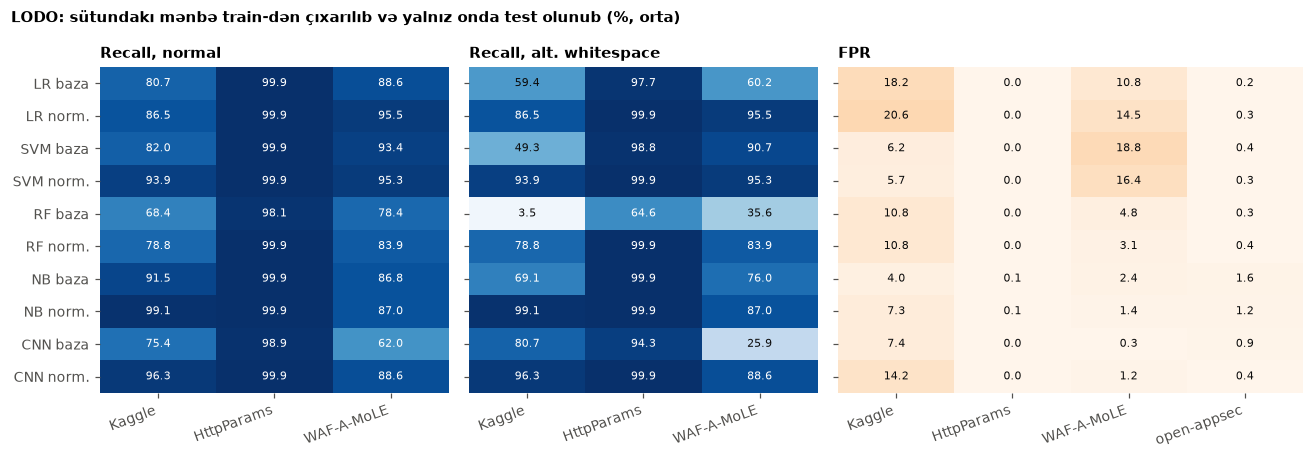

In [16]:
# LODO heatmap: recall (zərərli sinfi olan mənbələr) və FPR (hamısı), normal və alt. whitespace
mal_src = [s for s in SRC if s != "open-appsec"]
panels = [("recall", "normal", mal_src, "Recall, normal"), ("recall", "alt_whitespace", mal_src, "Recall, alt. whitespace"),
          ("fpr", "normal", SRC, "FPR")]
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), gridspec_kw={"width_ratios": [3, 3, 4]})
for ax, (m, inp, srcs, ttl) in zip(axes, panels):
    M = np.array([[100 * a_lodo.loc[(f"LODO: {s}", inp, k), (m, "mean")] for s in srcs] for k in v3.MODEL_ORDER])
    cmap = "Blues" if m == "recall" else "Oranges"
    ax.imshow(M, cmap=cmap, vmin=0, vmax=100, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.1f}", ha="center", va="center", fontsize=7,
                    color="white" if M[i, j] > 60 else "#0b0b0b")
    ax.set_xticks(range(len(srcs)), srcs, rotation=20, ha="right")
    ax.set_yticks(range(len(v3.MODEL_ORDER)), v3.MODEL_ORDER if ax is axes[0] else [])
    ax.set_title(ttl, loc="left")
    for sp in ax.spines.values(): sp.set_visible(False)
fig.suptitle("LODO: sütundakı mənbə train-dən çıxarılıb və yalnız onda test olunub (%, orta)", x=0.01, ha="left",
             fontweight="bold", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "17_lodo_heatmap.png")
plt.show()

## 6. Artefakt yoxlaması — birləşdirilmiş datasetdə baza LR-in ən güclü 20 n-gram-ı (seed 42)

,zərərli_ngram,zərərli_coef,zərərli_kateqoriya,təmiz_ngram,təmiz_coef,təmiz_kateqoriya
0,"'""'",11.418,durğu / digər,' -',-4.506,boşluq / tək simvol + boşluq
1,')',10.791,durğu / digər,' -1',-3.776,durğu / digər
2,"""'""",9.602,durğu / digər,'-1',-3.538,durğu / digər
3,'=',8.025,durğu / digər,'t -',-3.037,durğu / digər
4,') ',7.325,boşluq / tək simvol + boşluq,'it -',-3.032,durğu / digər
5,'--',7.285,şərh,'mit -',-3.032,durğu / digər
6,' ',7.214,boşluq / tək simvol + boşluq,'t',-2.889,tək / iki hərf (təsadüfi literal?)
7,"','",6.358,durğu / digər,'= -',-2.886,durğu / digər
8,"' ""'",6.088,boşluq / tək simvol + boşluq,'m',-2.849,tək / iki hərf (təsadüfi literal?)
9,'(',6.026,durğu / digər,'f',-2.820,tək / iki hərf (təsadüfi literal?)


zərərli tərəfin top-20 kateqoriyaları: {'durğu / digər': np.int64(10), 'boşluq / tək simvol + boşluq': np.int64(7), 'şərh': np.int64(2), 'SQL açar sözü (parça)': np.int64(1)}
təmiz tərəfin top-20 kateqoriyaları: {'durğu / digər': np.int64(10), 'tək / iki hərf (təsadüfi literal?)': np.int64(7), 'rəqəm': np.int64(2), 'boşluq / tək simvol + boşluq': np.int64(1)}
DİQQƏT (zərərli): top-20-də 9 format n-gram-ı var — ') ' [boşluq / tək simvol + boşluq], '--' [şərh], ' ' [boşluq / tək simvol + boşluq], ' "' [boşluq / tək simvol + boşluq], "' " [boşluq / tək simvol + boşluq], " '" [boşluq / tək simvol + boşluq], '#' [şərh], ' a' [boşluq / tək simvol + boşluq], '1 ' [boşluq / tək simvol + boşluq]
DİQQƏT (təmiz): top-20-də 8 format n-gram-ı var — ' -' [boşluq / tək simvol + boşluq], 't' [tək / iki hərf (təsadüfi literal?)], 'm' [tək / iki hərf (təsadüfi literal?)], 'f' [tək / iki hərf (təsadüfi literal?)], 'i' [tək / iki hərf (təsadüfi literal?)], 'g' [tək / iki hərf (təsadüfi literal?)], 'j' [tə

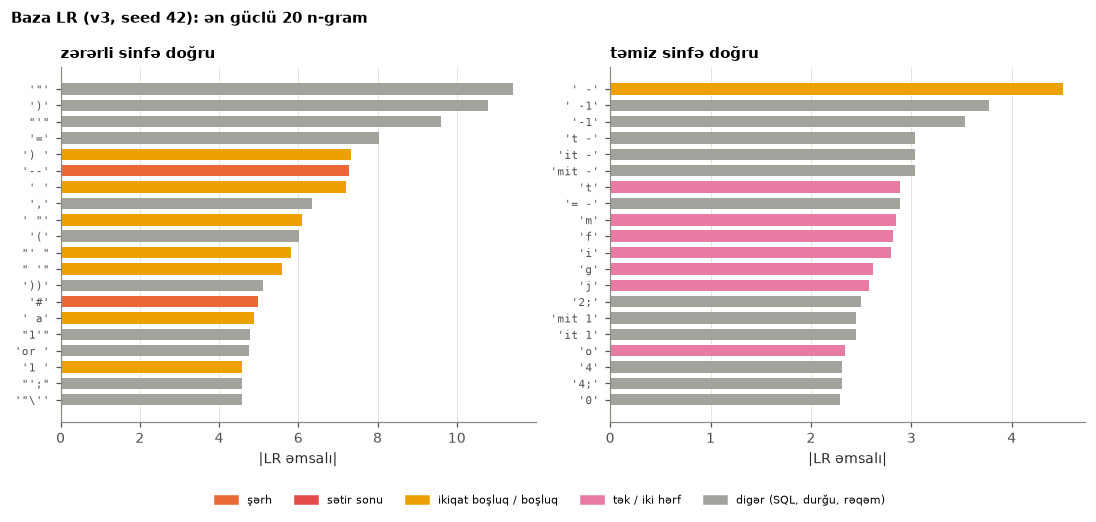

In [17]:
import joblib
models42, _ = joblib.load(v3.MODELS / "tfidf_main_base_42.joblib")
lr = models42["LR baza"]
vocab = np.array(lr.vec.get_feature_names_out()); coef = lr.clf.coef_[0]
top_m, top_b = np.argsort(-coef)[:20], np.argsort(coef)[:20]
ng = pd.DataFrame({
    "zərərli_ngram": [repr(g) for g in vocab[top_m]], "zərərli_coef": coef[top_m].round(3),
    "zərərli_kateqoriya": [v3.ngram_category(g) for g in vocab[top_m]],
    "təmiz_ngram": [repr(g) for g in vocab[top_b]], "təmiz_coef": coef[top_b].round(3),
    "təmiz_kateqoriya": [v3.ngram_category(g) for g in vocab[top_b]],
})
ng.to_csv(RES / "17_lr_base_top20_ngrams.csv", index=False)
display(ng)
for side in ("zərərli", "təmiz"):
    vc = ng[f"{side}_kateqoriya"].value_counts()
    print(f"{side} tərəfin top-20 kateqoriyaları:", dict(vc))
flag = {"şərh", "sətir sonu", "tək / iki hərf (təsadüfi literal?)", "ikiqat boşluq", "boşluq / tək simvol + boşluq"}
for side in ("zərərli", "təmiz"):
    hits = ng[ng[f"{side}_kateqoriya"].isin(flag)]
    if len(hits):
        print(f"DİQQƏT ({side}): top-20-də {len(hits)} format n-gram-ı var — " +
              ", ".join(f"{g} [{c}]" for g, c in zip(hits[f'{side}_ngram'], hits[f'{side}_kateqoriya'])))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
cat_color = {"şərh": "#eb6834", "sətir sonu": "#e34948", "ikiqat boşluq": "#eda100",
             "boşluq / tək simvol + boşluq": "#eda100", "tək / iki hərf (təsadüfi literal?)": "#e87ba4"}
for ax, side, sign in ((axes[0], "zərərli", 1), (axes[1], "təmiz", -1)):
    g = ng[f"{side}_ngram"]; c = ng[f"{side}_coef"].abs(); k = ng[f"{side}_kateqoriya"]
    ax.barh(range(20), c, color=[cat_color.get(x, "#a3a29c") for x in k], height=0.7)
    ax.set_yticks(range(20), g, fontfamily="monospace", fontsize=7.5); ax.invert_yaxis()
    ax.xaxis.grid(True); ax.set_axisbelow(True)
    ax.set_xlabel("|LR əmsalı|"); ax.set_title(f"{side} sinfə doğru", loc="left")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=v, label=k) for k, v in list(cat_color.items())[:2] + [("ikiqat boşluq / boşluq", "#eda100"),
                                                                                       ("tək / iki hərf", "#e87ba4"),
                                                                                       ("digər (SQL, durğu, rəqəm)", "#a3a29c")]],
           loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.02), fontsize=7.5)
fig.suptitle("Baza LR (v3, seed 42): ən güclü 20 n-gram", x=0.01, ha="left", fontweight="bold", fontsize=10)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(FIG / "17_lr_base_top_ngrams.png")
plt.show()